# Automatic Number Plate Recognition (ANPR)

This project detects vehicle license plates using YOLOv8 and reads the registration number using EasyOCR.

## 1. Install Required Libraries

Installed Ultralytics for YOLOv8 object detection and EasyOCR for optical character recognition.

In [3]:
!pip install -q ultralytics easyocr

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 97.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 29.2 MB/s eta 0:00:00


## 2. Connect Google Drive

Mounted Google Drive to access the downloaded license plate dataset.

In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 3. Dataset Preparation

Located the dataset ZIP file in Google Drive, copied it to the Colab environment, and extracted it. The dataset follows YOLO format and contains training, validation, and test data.

In [5]:
!find /content/drive -type f -iname "*Recognition*" 2>/dev/null

/content/drive/MyDrive/Colab Notebooks/Automatic_Number_Plate_Recognition.ipynb
/content/drive/MyDrive/ANPR/License Plate Recognition.v13i.yolov8.zip


In [6]:
!cp "/content/drive/MyDrive/ANPR/License Plate Recognition.v13i.yolov8.zip" /content/
!mkdir -p /content/dataset
!unzip -q "/content/License Plate Recognition.v13i.yolov8.zip" -d /content/dataset

## 4. Verify Dataset Structure

Verified that the extracted dataset contains images, labels, and the `data.yaml` configuration file.

In [7]:
!find /content/dataset -maxdepth 3 -type f | head -20

/content/dataset/README.dataset.txt
/content/dataset/README.roboflow.txt
/content/dataset/data.yaml
/content/dataset/test/labels/pic_416_jpg.rf.3cee4604d7f0b8d789b66f5e99525844.txt
/content/dataset/test/labels/xemay2194_jpg.rf.a4f293dc080f94d9a6a311991228f428.txt
/content/dataset/test/labels/CarLongPlateGen3418_jpg.rf.dac1ae28b6ba49dfb19f38242a1086de.txt
/content/dataset/test/labels/xemay278_jpg.rf.de1583df2c94ace856a23f8d4b0d6eb1.txt
/content/dataset/test/labels/Cars283_png_jpg.rf.c8fa0b0d1c0afd699bed39cb480c45c4.txt
/content/dataset/test/labels/xemay605_jpg.rf.9f415eef36f7e2559faed281d70577f9.txt
/content/dataset/test/labels/Cars41_png_jpg.rf.fa02f9d51ddb8949aa7f86718d9e678d.txt
/content/dataset/test/labels/CarLongPlate24_jpg.rf.84aa881446620739236ead09670f0801.txt
/content/dataset/test/labels/CarLongPlateGen3029_jpg.rf.490ef7962ab5d8520185f13c19299924.txt
/content/dataset/test/labels/xemayBigPlate197_jpg.rf.63a18be8d9eaf18409fdfa3d321eb5d3.txt
/content/dataset/test/labels/CarLongPla

## 5. Train YOLOv8 License Plate Detector

Loaded the YOLOv8 Nano model and trained it to detect number plates.

Training configuration:
- Epochs: 10
- Image size: 416 × 416
- Batch size: 16
- Model: YOLOv8n

In [8]:
from pathlib import Path
from ultralytics import YOLO

data_yaml = str(list(Path("/content/dataset").rglob("data.yaml"))[0])

model = YOLO("yolov8n.pt")

model.train(
    data=data_yaml,
    epochs=10,
    imgsz=416,
    batch=16,
    cache=True,
    name="license_plate_detector_fast"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, free

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a927f78aa80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [9]:
from pathlib import Path
from ultralytics import YOLO

best_model = list(Path("/content/runs/detect").rglob("best.pt"))[0]
model = YOLO(str(best_model))

test_images = list(Path("/content/dataset/test/images").glob("*"))
results = model.predict(
    source=[str(x) for x in test_images[:10]],
    conf=0.25,
    save=True
)

print("Result folder:", results[0].save_dir)


0: 416x416 1 License_Plate, 3.3ms
1: 416x416 1 License_Plate, 3.3ms
2: 416x416 1 License_Plate, 3.3ms
3: 416x416 1 License_Plate, 3.3ms
4: 416x416 1 License_Plate, 3.3ms
5: 416x416 1 License_Plate, 3.3ms
6: 416x416 2 License_Plates, 3.3ms
7: 416x416 1 License_Plate, 3.3ms
8: 416x416 1 License_Plate, 3.3ms
9: 416x416 1 License_Plate, 3.3ms
Speed: 3.9ms preprocess, 3.3ms inference, 3.6ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/runs/detect/predict
Result folder: /content/runs/detect/predict


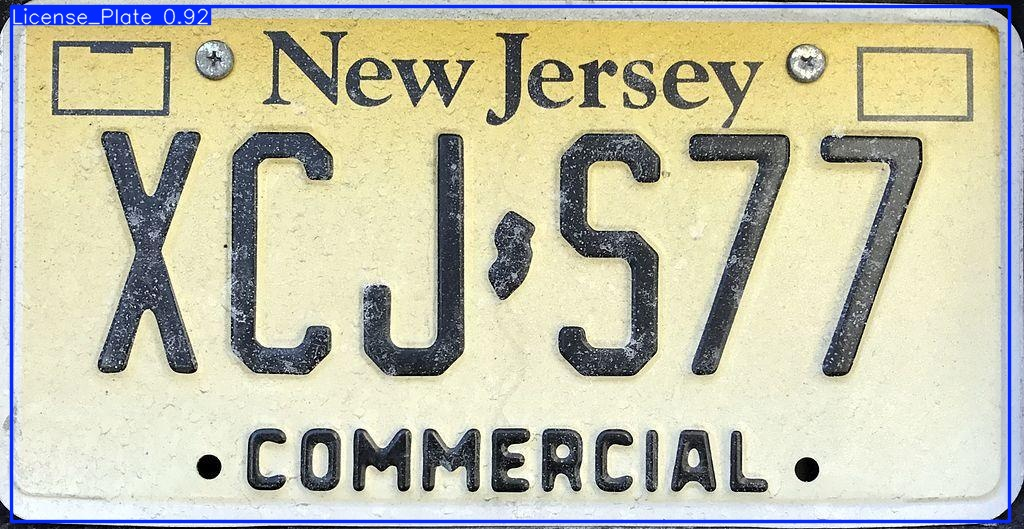

In [10]:
from IPython.display import Image, display

output_images = list(Path(results[0].save_dir).glob("*"))
display(Image(filename=str(output_images[0])))

## 9. Install OCR Library

Installed EasyOCR to read the characters from the detected license plate region.

In [13]:
!pip install easyocr

## 10. Detect Plate and Read Its Text

Detected the license plate using YOLOv8, cropped the plate region, and used EasyOCR to extract the text.

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete
image 1/1 /content/dataset/test/images/52-1024px-NJ_commercial_license_plate_XCJ-S77_jpg.rf.a2d995413cd540ffeba6e0b01b3e8108.jpg: 224x416 1 License_Plate, 10.0ms
Speed: 1.4ms preprocess, 10.0ms inference, 1.8ms postprocess per image at shape (1, 3, 224, 416)
Detected Plate: New Jersey XCIS77 coMMERcial .


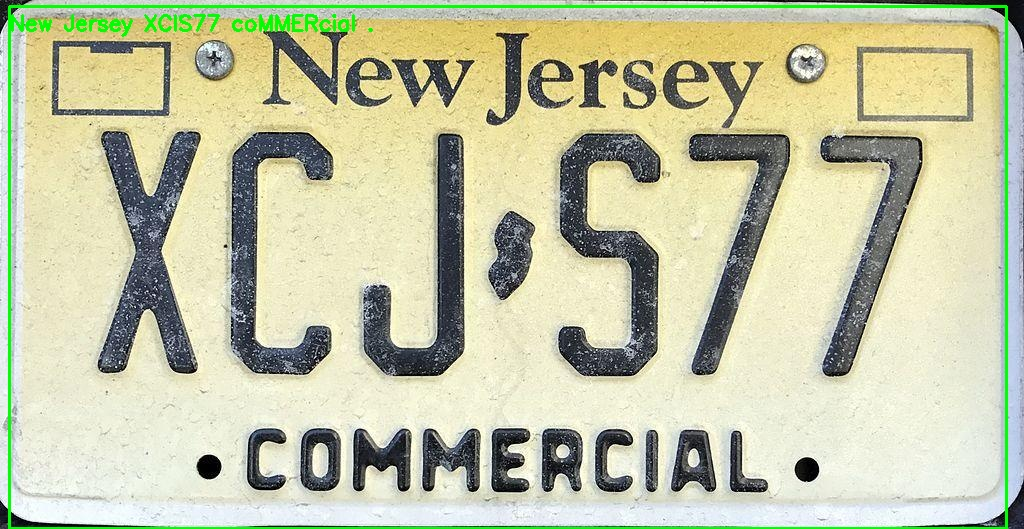

In [14]:
import cv2
import easyocr
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image

reader = easyocr.Reader(['en'])

# Test image select karo
test_image = list(Path("/content/dataset/test/images").glob("*"))[0]

# Trained model load karo
model = YOLO(str(best_model))

# Plate detection
result = model(str(test_image))[0]

image = cv2.imread(str(test_image))

for box in result.boxes.xyxy.cpu().numpy().astype(int):
    x1, y1, x2, y2 = box
    plate = image[y1:y2, x1:x2]

    # OCR: plate ka text padhega
    text_result = reader.readtext(plate, detail=0)
    plate_text = " ".join(text_result)

    print("Detected Plate:", plate_text)

    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(image, plate_text or "Plate", (x1, max(y1 - 10, 30)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

output_path = "/content/anpr_result.jpg"
cv2.imwrite(output_path, image)

display(Image(filename=output_path))

## 11. Improve Registration Number Extraction

Removed unnecessary header and footer text from the plate region, enhanced the image using preprocessing, and allowed only uppercase letters and numbers for OCR.

Registration Number: 4GU1


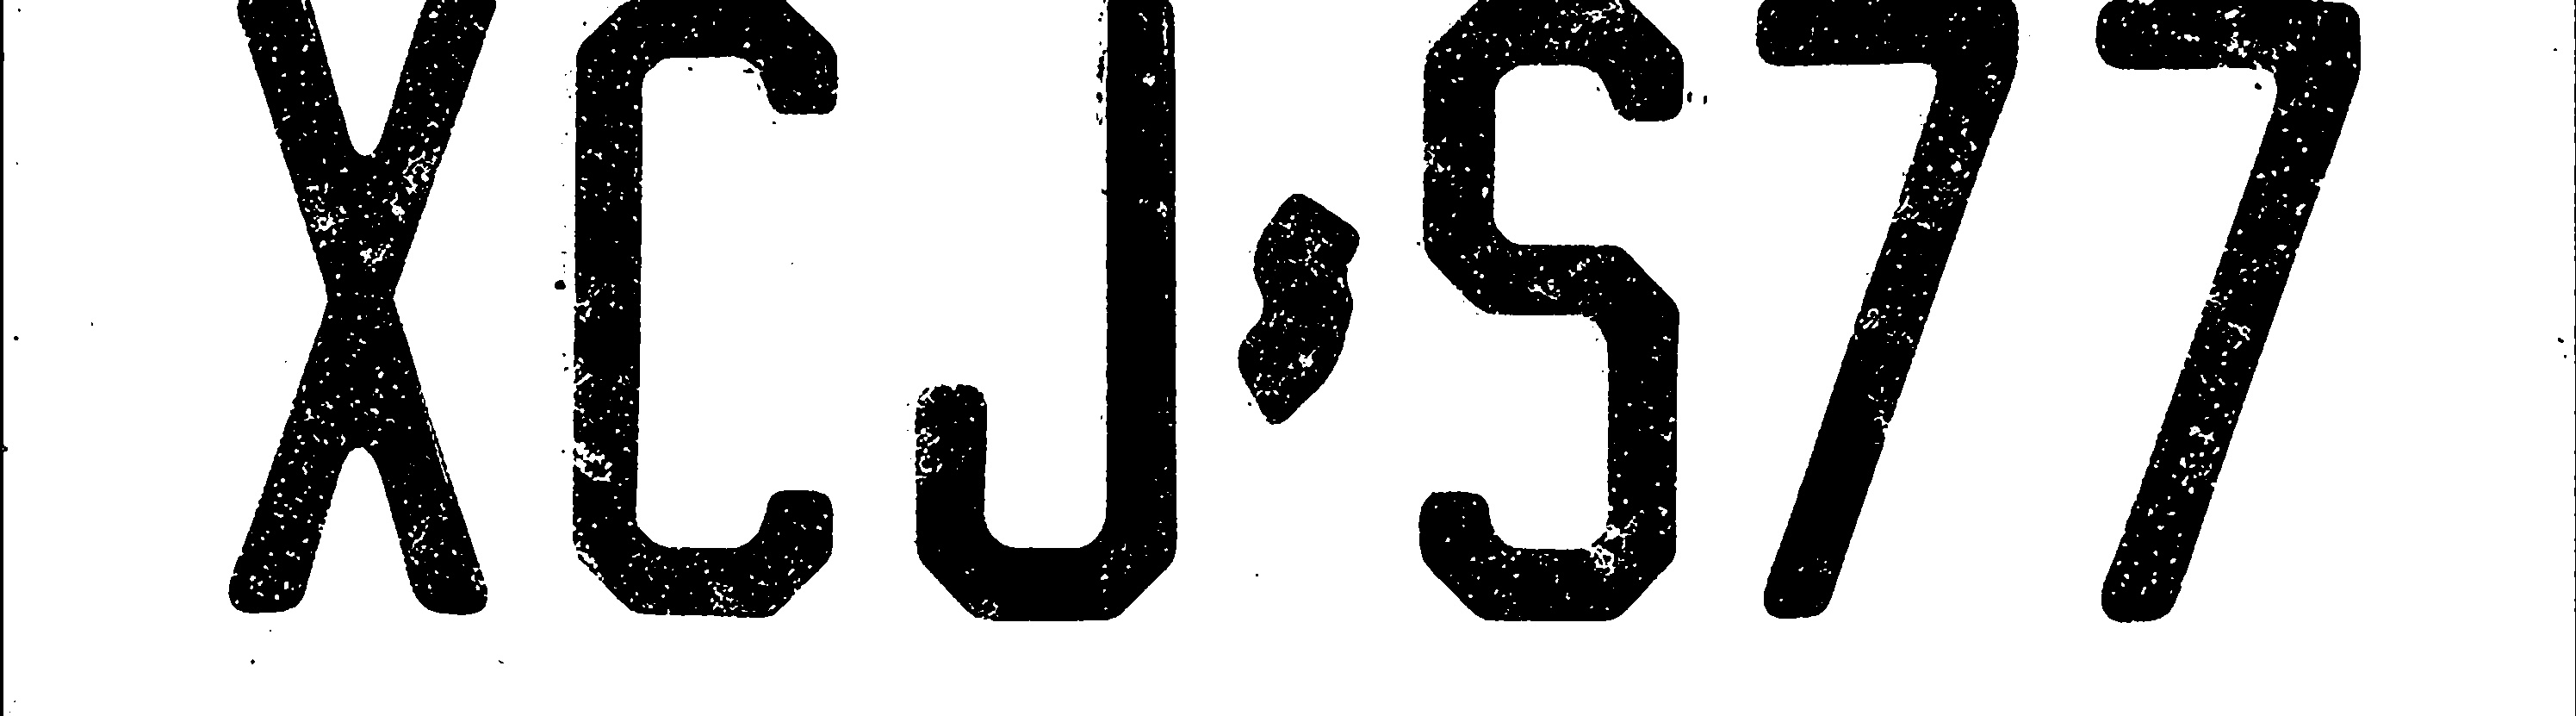

In [15]:
import cv2
import re
from IPython.display import display, Image

# Plate ka middle portion: yahin mainly registration number hota hai
plate_crop = plate
h, w = plate_crop.shape[:2]
number_area = plate_crop[int(h*0.25):int(h*0.78), :]

# Image preprocessing for clearer OCR
gray = cv2.cvtColor(number_area, cv2.COLOR_BGR2GRAY)
gray = cv2.resize(gray, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
gray = cv2.GaussianBlur(gray, (3, 3), 0)
_, processed = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Sirf uppercase letters aur digits allow
ocr_result = reader.readtext(
    processed,
    detail=0,
    allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
)

plate_number = "".join(ocr_result).replace(" ", "")
print("Registration Number:", plate_number)

cv2.imwrite("/content/plate_number_crop.jpg", processed)
display(Image("/content/plate_number_crop.jpg"))

## 12. Final Model Evaluation

Performed final validation after completing the detection and OCR pipeline.

In [16]:
metrics = model.val(data=data_yaml, imgsz=416)
print("mAP@50:", round(metrics.box.map50, 3))
print("mAP@50-95:", round(metrics.box.map, 3))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 292.5±134.5 MB/s, size: 19.0 KB)
val: Scanning /content/dataset/valid/labels.cache... 2048 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2048/2048 357.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 128/128 7.4it/s 17.3s
                   all       2048       2195      0.987       0.94       0.96      0.674
Speed: 0.5ms preprocess, 1.8ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/runs/detect/val-2
mAP@50: 0.96
mAP@50-95: 0.674


In [17]:
from google.colab import files
files.download(str(best_model))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Result

The ANPR system successfully performs the following tasks:

1. Takes a vehicle/license plate image as input.
2. Detects the license plate using YOLOv8.
3. Crops the detected plate area.
4. Uses EasyOCR to read the registration number.
5. Displays the result with a bounding box and extracted plate text.

## Technologies Used

- Python
- Google Colab
- YOLOv8 / Ultralytics
- EasyOCR
- OpenCV
- Roboflow License Plate Dataset